# Sample non-dimensional planetary-geostrophic problem

This notebook specifies a PG problem with a broad zonal depth slope and an off-center Gaussian seamount, solves for surface pressure, samples the full 3D solution, writes VTK files, and plots the solution and diagnostic balances. The bathymetry remains strictly positive while varying in both horizontal directions, so the example exercises the full $H(x,y)$ API.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, "..", "PlanetaryGeostrophy"))
using PlanetaryGeostrophy

  Activating project at `~/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy`


In [2]:
Lx, Ly = 2.0, 1.5
H0 = 1.0
boundary = rectangle_boundary(Lx, Ly)
parameters = PGParameters(0.02, 0.20; viscosity=1.0, diffusivity=1.0)

# A broad zonal slope plus a smooth off-center seamount exercises H(x, y).
depth_slope = 0.15
seamount_amplitude = 0.25
seamount_center = (-0.25Lx, 0.10Ly)
seamount_width = (0.25Lx, 0.30Ly)
seamount(x, y) = exp(
    -((x - seamount_center[1]) / seamount_width[1])^2 -
    ((y - seamount_center[2]) / seamount_width[2])^2
)
depth(x, y) = H0 * (
    1 + depth_slope * x / Lx - seamount_amplitude * seamount(x, y)
)
depth_x(x, y) = H0 * (
    depth_slope / Lx +
    2seamount_amplitude * (x - seamount_center[1]) /
    seamount_width[1]^2 * seamount(x, y)
)
depth_y(x, y) = H0 * (
    2seamount_amplitude * (y - seamount_center[2]) /
    seamount_width[2]^2 * seamount(x, y)
)

problem = PGProblem(
    parameters=parameters,
    depth=depth,
    depth_x=depth_x,
    depth_y=depth_y,
    coriolis=(x, y) -> 1.0 + 0.15y,
    coriolis_x=(x, y) -> 0.0,
    coriolis_y=(x, y) -> 0.15,
    wind_stress=(x, y) -> 1e-3 * cos(pi * y / Ly) + 0im,
    restoring_buoyancy=(x, y, z) -> 1e-2z + 2e-3 * sin(pi * x / Lx),
    surface_buoyancy=(x, y) -> 2e-3 * cos(pi * x / Lx) * cos(pi * y / Ly),
    boundary=boundary,
)

PGProblem{PGParameters{Float64}, typeof(depth), var"#28#29", var"#30#31", var"#32#33", var"#34#35", PlanetaryGeostrophy.var"#89#90"{PlanetaryGeostrophy.var"#automatic_y##0#automatic_y##1"{PlanetaryGeostrophy.var"#85#86"{var"#34#35"}}, PlanetaryGeostrophy.var"#automatic_x##0#automatic_x##1"{PlanetaryGeostrophy.var"#87#88"{var"#34#35"}}}, var"#36#37", var"#38#39", typeof(depth_x), typeof(depth_y), Vector{Tuple{Float64, Float64}}, PlanetaryGeostrophy.var"#83#84"{Vector{Tuple{Float64, Float64}}}}(PGParameters{Float64}(0.02, 0.2, 1.0, 1.0), Main.depth, var"#28#29"(), var"#30#31"(), var"#32#33"(), var"#34#35"(), PlanetaryGeostrophy.var"#89#90"{PlanetaryGeostrophy.var"#automatic_y##0#automatic_y##1"{PlanetaryGeostrophy.var"#85#86"{var"#34#35"}}, PlanetaryGeostrophy.var"#automatic_x##0#automatic_x##1"{PlanetaryGeostrophy.var"#87#88"{var"#34#35"}}}(PlanetaryGeostrophy.var"#automatic_y##0#automatic_y##1"{PlanetaryGeostrophy.var"#85#86"{var"#34#35"}}(PlanetaryGeostrophy.var"#85#86"{var"#34#35"}(v

In [3]:
solution = solve_pg(
    problem;
    mesh_file=joinpath(@__DIR__, "sample_pg_pressure.msh"),
    mesh_resolution=0.20,
    overwrite_mesh=true,
)

┌ Info: PG solve started
│   Ek = 0.02
│   Γ = 0.2
│   viscosity = 1.0
│   diffusivity = 1.0
│   pressure_order = 2
│   mesh_resolution = 0.2
│   mesh_file = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_pressure.msh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:227
┌ Info: Starting generating surface mesh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16


Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000135333s, CPU 0.000122s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00203787s, CPU 0.002002s)
Info    : 117 nodes 236 elements
Info    : Writing '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_pressure.msh'...
Info    : Done writing '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_pressure.msh'
Info    : Reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/Plan

┌ Info: Completed generating surface mesh
│   seconds = 0.045
│   allocated_mib = 3.54
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Starting loading analytical Green-function kernels
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed loading analytical Green-function kernels
│   seconds = 0.0
│   allocated_mib = 0.0
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Surface-pres

PGSolution{PGProblem{PGParameters{Float64}, typeof(depth), var"#28#29", var"#30#31", var"#32#33", var"#34#35", PlanetaryGeostrophy.var"#89#90"{PlanetaryGeostrophy.var"#automatic_y##0#automatic_y##1"{PlanetaryGeostrophy.var"#85#86"{var"#34#35"}}, PlanetaryGeostrophy.var"#automatic_x##0#automatic_x##1"{PlanetaryGeostrophy.var"#87#88"{var"#34#35"}}}, var"#36#37", var"#38#39", typeof(depth_x), typeof(depth_y), Vector{Tuple{Float64, Float64}}, PlanetaryGeostrophy.var"#83#84"{Vector{Tuple{Float64, Float64}}}}, PlanetaryGeostrophy.VelocityFieldPrototype.SymbolicKernels{PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##0#load_symbolic_kernels##1", PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##2#load_symbolic_kernels##3", PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##4#load_symbolic_kernels##5", PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##6#load_symbolic_kernels##7", PlanetaryGeostrophy.VelocityFie

In [4]:
x = range(-0.99Lx / 2, 0.99Lx / 2; length=64)
y = range(-0.99Ly / 2, 0.99Ly / 2; length=64)
z = range(-H0, 0.0; length=64)
fields = sample_solution(solution, x, y, z)

┌ Info: Solution sampling started
│   Nx = 64
│   Ny = 64
│   Nz = 64
│   grid_points = 262144
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1065
┌ Info: Starting sampling surface pressure and bathymetry
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed sampling surface pressure and bathymetry
│   seconds = 0.518
│   allocated_mib = 332.58
│   gc_seconds = 0.021
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Starting sampling 

PGFields{Vector{Float64}, Vector{Float64}, Vector{Float64}, @NamedTuple{surface_fields::@NamedTuple{seconds::Float64, allocated_mib::Float64, gc_seconds::Float64}, horizontal_velocity_and_buoyancy::@NamedTuple{seconds::Float64, allocated_mib::Float64, gc_seconds::Float64}, vertical_velocity::@NamedTuple{seconds::Float64, allocated_mib::Float64, gc_seconds::Float64}, total_seconds::Float64, wet_points::Int64, wet_points_per_second::Float64}}([-0.99, -0.9585714285714285, -0.9271428571428572, -0.8957142857142857, -0.8642857142857143, -0.8328571428571429, -0.8014285714285714, -0.77, -0.7385714285714285, -0.7071428571428572  …  0.7071428571428572, 0.7385714285714285, 0.77, 0.8014285714285714, 0.8328571428571429, 0.8642857142857143, 0.8957142857142857, 0.9271428571428572, 0.9585714285714285, 0.99], [-0.7424999999999999, -0.7189285714285714, -0.6953571428571428, -0.6717857142857142, -0.6482142857142856, -0.624642857142857, -0.6010714285714285, -0.5774999999999999, -0.5539285714285714, -0.5303

┌ Info: Writing sampled PG solution
│   prefix = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1948
┌ Info: Starting writing 3D VTK fields
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed writing 3D VTK fields
│   seconds = 0.57
│   allocated_mib = 50.6
│   gc_seconds = 0.011
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostr

(volume = "/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_3D_solution.vtr", surface = "/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_surface_solution.vtr", timings = (volume = (seconds = 0.569843667, allocated_mib = 50.600830078125, gc_seconds = 0.01145925), surface = (seconds = 0.144387042, allocated_mib = 10.15167236328125, gc_seconds = 0.0), total_seconds = 0.7158222198486328))

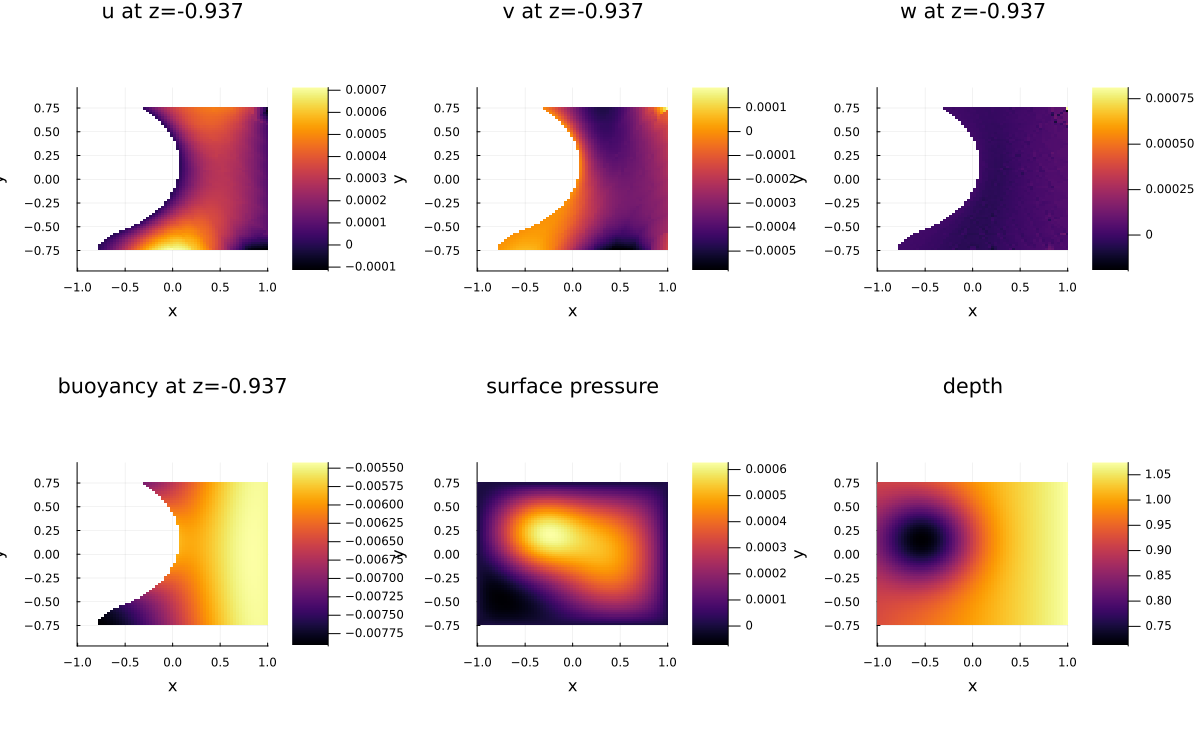

In [5]:
files = write_solution(fields, joinpath(@__DIR__, "sample_pg"))
figure = plot_solution(
    fields;
    sigma_level=0.5,
    output=joinpath(@__DIR__, "sample_pg_solution.png"),
)
display(files)
display(figure)

In [6]:
# The direct analytical diagnostic quadratures are more expensive than field sampling.
diagnostic_stride = 4
diagnostic_x = x[1:diagnostic_stride:end]
diagnostic_y = y[1:diagnostic_stride:end]
diagnostics = compute_diagnostics(solution, diagnostic_x, diagnostic_y)
display(performance_summary(diagnostics))

┌ Info: PG diagnostic calculation started
│   Nx = 16
│   Ny = 16
│   horizontal_points = 256
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1148
┌ Info: Transport streamfunction solve started
│   finite_element_order = 2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/SurfacePressureTools.jl:249
┌ Info: Starting constructing streamfunction finite-element spaces
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/SurfacePressureTools.jl:12
┌ Info: Completed constructing streamfunction finite-element spaces
│   seconds = 

(streamfunction = (finite_element_setup = (seconds = 1.019908, allocated_mib = 497.21473693847656, gc_seconds = 0.028508416), current_projection = (seconds = 15.324809875, allocated_mib = 2911.381637573242, gc_seconds = 0.127618043), operator_assembly = (seconds = 2.904362875, allocated_mib = 362.3498992919922, gc_seconds = 0.0154335), linear_solve = (seconds = 0.0006555, allocated_mib = 0.74066162109375, gc_seconds = 0.0), total_seconds = 19.314069986343384), bottom_stress_projection = (setup = (seconds = 0.069832333, allocated_mib = 14.692413330078125, gc_seconds = 0.0), interpolation = (seconds = 13.808061208, allocated_mib = 20681.6219329834, gc_seconds = 0.788915715), total_seconds = 13.910367965698242), sampling = (seconds = 1.593471125, allocated_mib = 379.2053680419922, gc_seconds = 0.020722083), total_seconds = 35.256288051605225, wet_points = 256, points_per_second = 160.65556255373, transport_projection_relative_l2 = 0.7810129141422183)

┌ Info: Plotting bottom stress
│   stride = 1
│   arrow_scale = 0.35
│   arrowhead_size = 0.08
│   output = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_bottom_stress.png
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2209
┌ Info: Starting rendering bottom-stress plot
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed rendering bottom-stress plot
│   seconds = 0.007
│   allocated_mib = 1.24
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-John

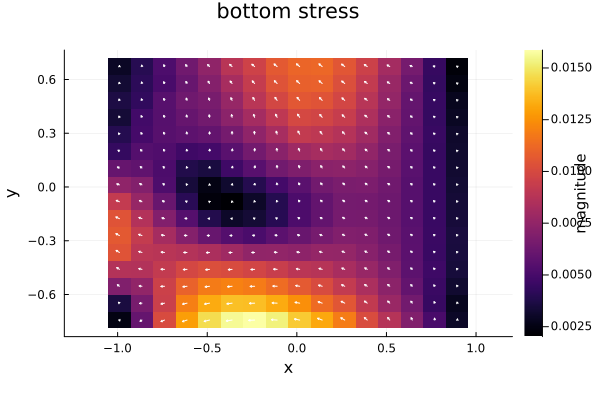

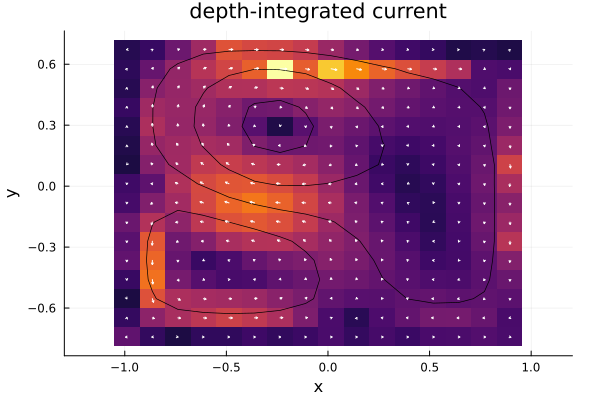

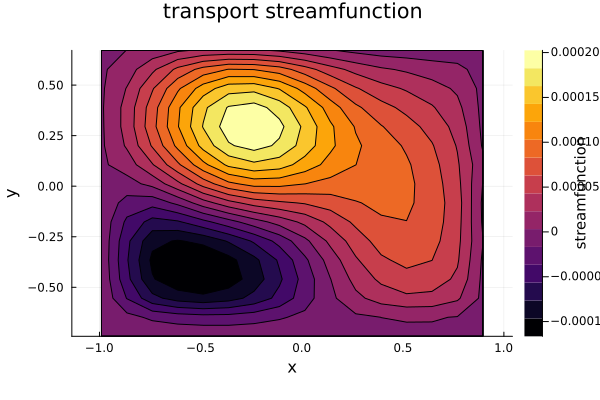

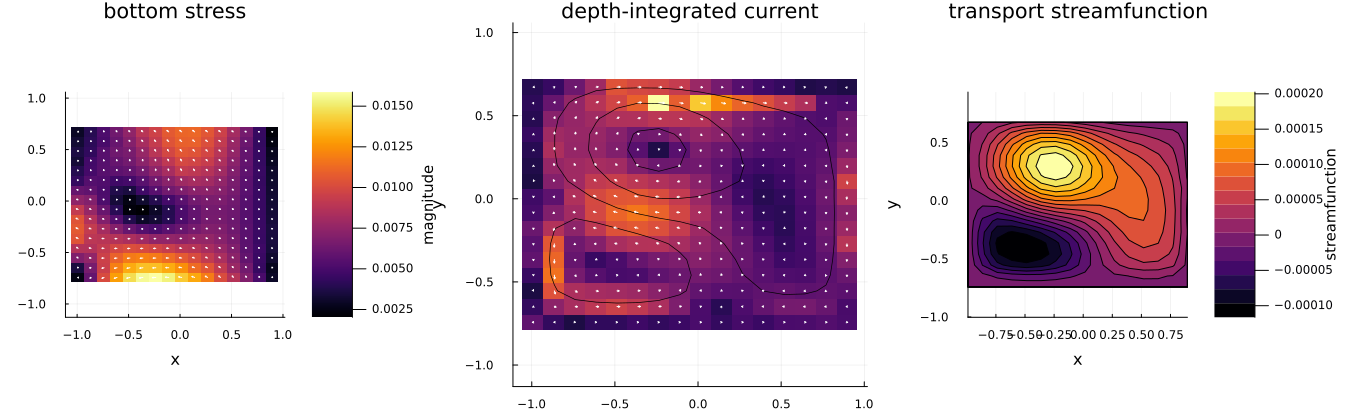

In [7]:
bottom_stress_figure = plot_bottom_stress(
    diagnostics;
    arrow_scale=0.35,
    output=joinpath(@__DIR__, "sample_pg_bottom_stress.png"),
)
transport_figure = plot_depth_integrated_current(
    diagnostics;
    arrow_scale=0.35,
    output=joinpath(@__DIR__, "sample_pg_transport.png"),
)
streamfunction_figure = plot_streamfunction(
    diagnostics;
    output=joinpath(@__DIR__, "sample_pg_streamfunction.png"),
)
diagnostic_figure = plot_diagnostics(
    diagnostics;
    arrow_scale=0.35,
    output=joinpath(@__DIR__, "sample_pg_diagnostics.png"),
)
display(bottom_stress_figure)
display(transport_figure)
display(streamfunction_figure)
display(diagnostic_figure)

## Depth-integrated momentum balance

Compute the terms corresponding to equations (32)--(33), together with bottom pressure $p_b$ and baroclinic potential energy $\chi$. The API consistently uses conventional oceanographic buoyancy, $\partial_z p=b$, with $p=p_s-\int_z^0 b\,dz$.

In [8]:
dim = compute_dim_diagnostics(solution, diagnostics)
display(performance_summary(dim))

┌ Info: DIM diagnostic calculation started
│   Nx = 16
│   Ny = 16
│   wet_points = 256
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1242
┌ Info: Starting sampling depth-integrated momentum terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: DIM diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 16
│   percent = 6.2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1267
┌ Info: DIM diagnostic sampling progress
│   rows_complete

(sampling = (seconds = 4.614284292, allocated_mib = 4796.894866943359, gc_seconds = 0.204886245), total_seconds = 4.615938901901245, x_relative_l2_residual = 4.501984296690298e-10, y_relative_l2_residual = 5.737513242436683e-10)

┌ Info: Plotting depth-integrated momentum balance
│   component = both
│   output = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_dim_balance.png
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2411
┌ Info: Starting rendering DIM balance plot
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed rendering DIM balance plot
│   seconds = 0.383
│   allocated_mib = 63.67
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/

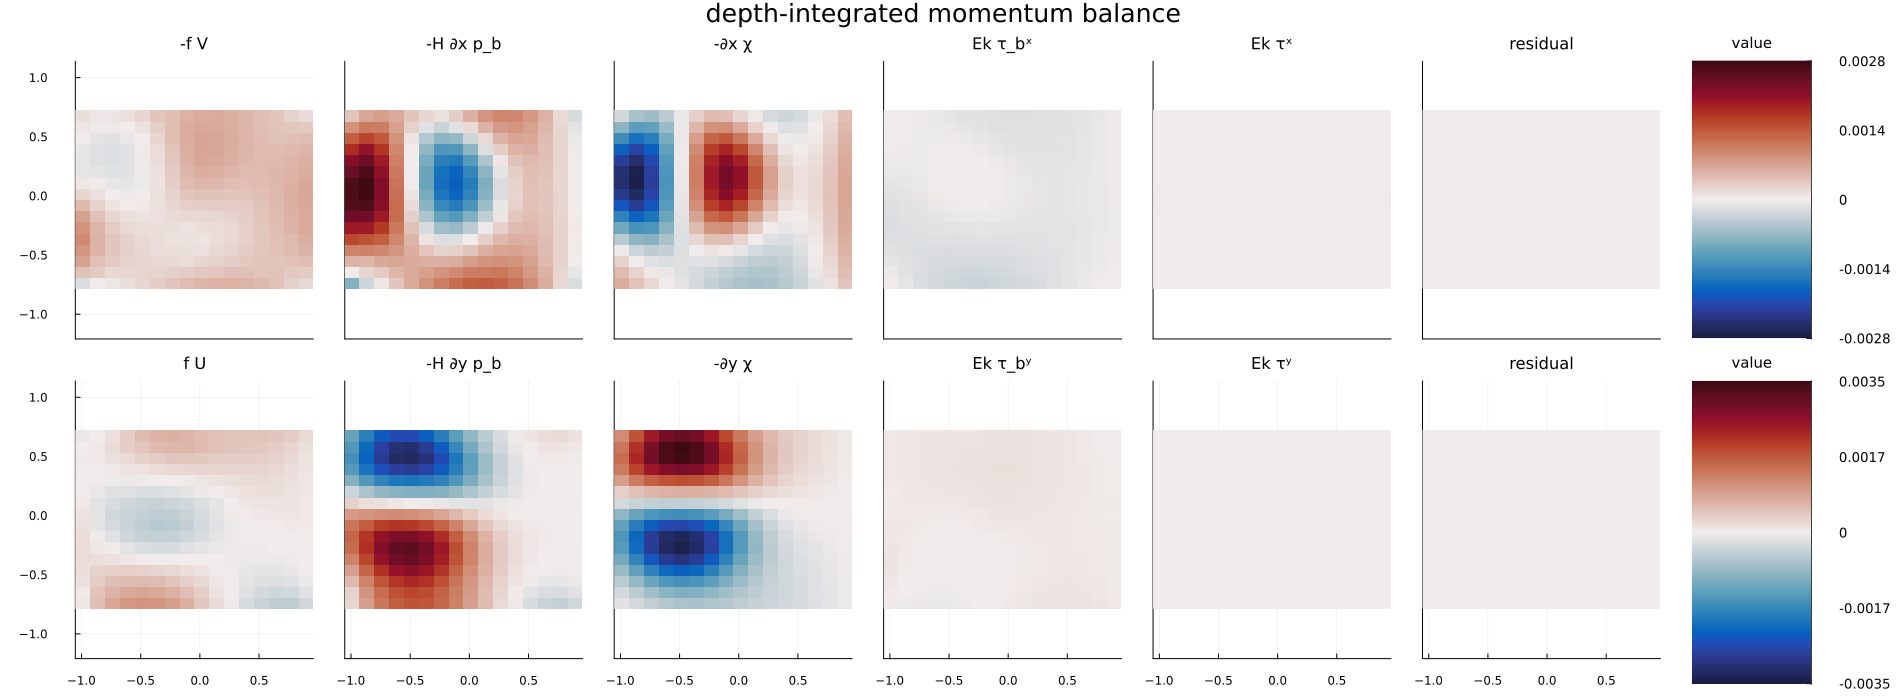

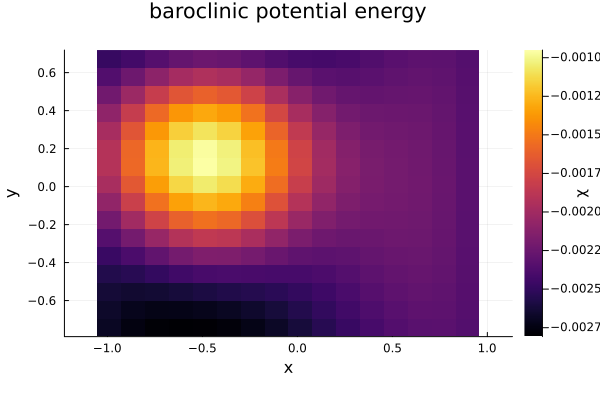

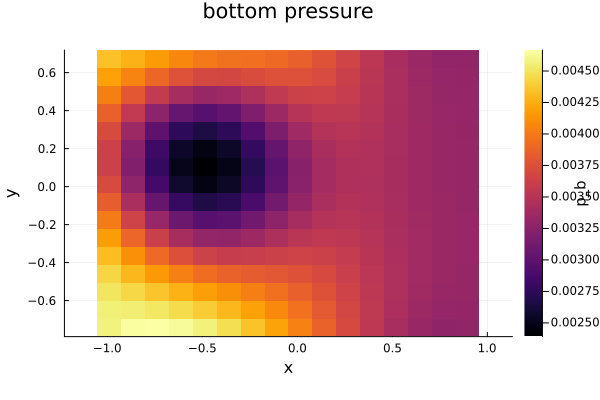

In [9]:
dim_balance_figure = plot_dim_balance(
    dim;
    output=joinpath(@__DIR__, "sample_pg_dim_balance.png"),
)
chi_figure = plot_baroclinic_potential_energy(
    dim;
    output=joinpath(@__DIR__, "sample_pg_chi.png"),
)
bottom_pressure_figure = plot_bottom_pressure(
    dim;
    output=joinpath(@__DIR__, "sample_pg_bottom_pressure.png"),
)
display(dim_balance_figure)
display(chi_figure)
display(bottom_pressure_figure)

## Barotropic vorticity balance

Compute and plot the transport-divergence, planetary-vorticity advection, bottom-pressure torque, boundary-stress curls, and closure residual in equation (36).

┌ Info: BV diagnostic calculation started
│   Nx = 16
│   Ny = 16
│   wet_points = 256
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1325
┌ Info: Starting sampling barotropic vorticity terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: BV diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 16
│   percent = 6.2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1337
┌ Info: BV diagnostic sampling progress
│   rows_completed = 2
│ 

(sampling = (seconds = 0.049859, allocated_mib = 27.392807006835938, gc_seconds = 0.0), total_seconds = 0.050215959548950195, relative_l2_residual = 0.07047727387203753)

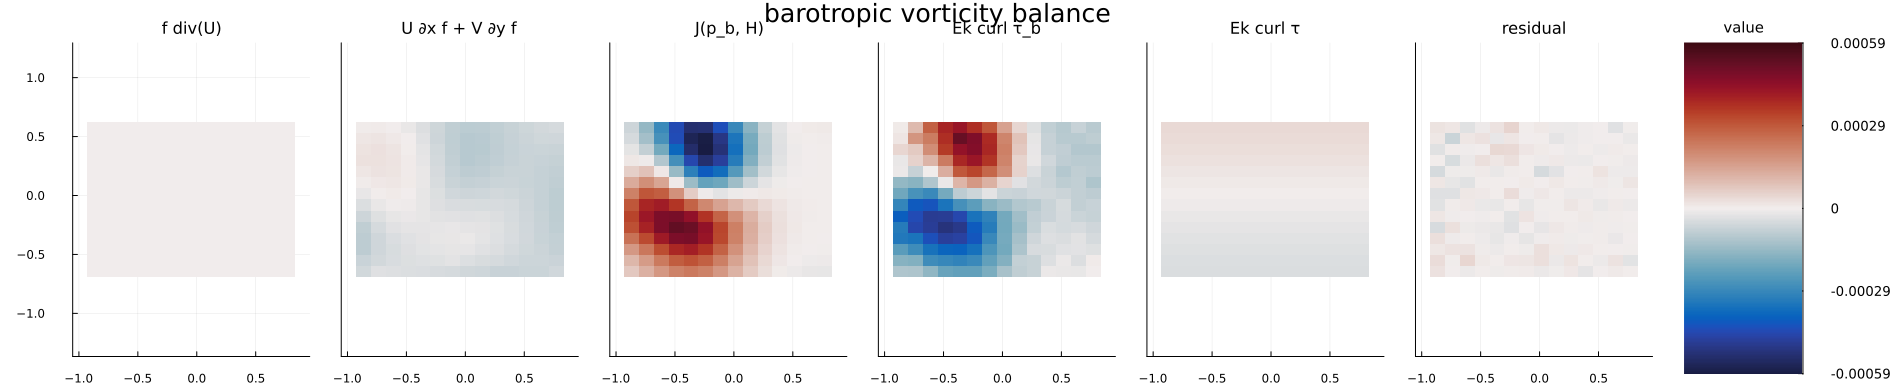

In [10]:
barotropic_vorticity = compute_barotropic_vorticity_diagnostics(
    solution, diagnostics,
)
display(performance_summary(barotropic_vorticity))

barotropic_vorticity_figure = plot_barotropic_vorticity_balance(
    barotropic_vorticity;
    output=joinpath(@__DIR__, "sample_pg_barotropic_vorticity_balance.png"),
)
display(barotropic_vorticity_figure)

## Depth-integrated vorticity balance

Compute and plot the planetary-vorticity advection, bottom vortex stretching, bottom-stress curl, surface-stress curl, and closure residual in equation (41).

┌ Info: Vorticity diagnostic calculation started
│   Nx = 16
│   Ny = 16
│   wet_points = 256
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1440
┌ Info: Starting sampling depth-integrated vorticity terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Vorticity diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 16
│   percent = 6.2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1467
┌ Info: Vorticity diagnostic sampling progres

(sampling = (seconds = 0.0707315, allocated_mib = 33.72265625, gc_seconds = 0.0), total_seconds = 0.07102704048156738, relative_l2_residual = 1.0604788087672536)

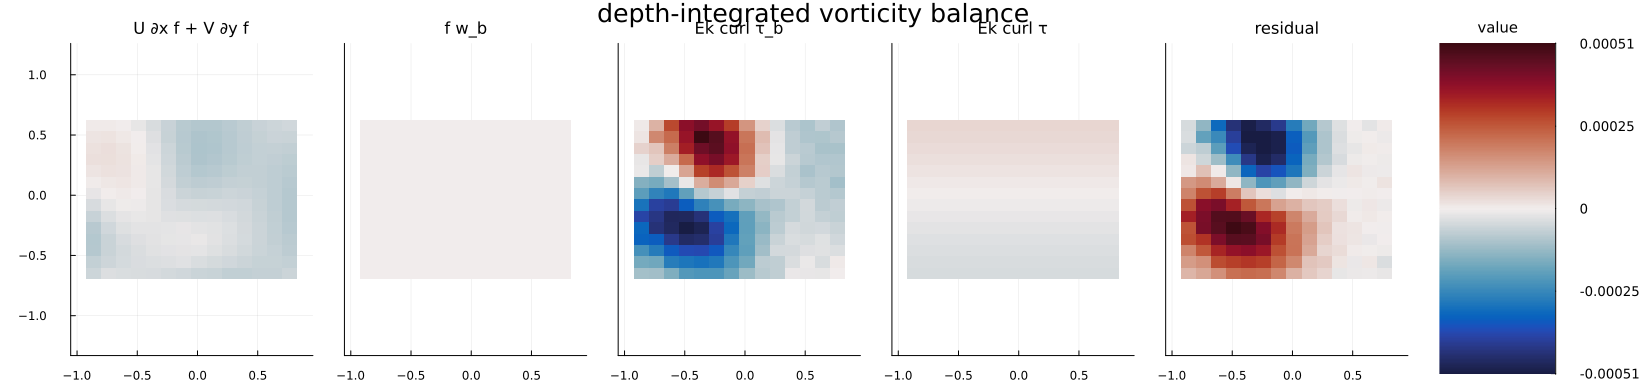

In [11]:
vorticity = compute_vorticity_diagnostics(solution, diagnostics)
display(performance_summary(vorticity))

vorticity_figure = plot_vorticity_balance(
    vorticity;
    output=joinpath(@__DIR__, "sample_pg_vorticity_balance.png"),
)
display(vorticity_figure)

## Geostrophic-contour vorticity balance

Compute and plot geostrophic-contour advection, JEBAR, the depth-weighted bottom- and surface-stress curls, and the closure residual in equation (43).

┌ Info: GCVB diagnostic calculation started
│   Nx = 16
│   Ny = 16
│   wet_points = 256
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1554
┌ Info: Starting sampling geostrophic-contour vorticity terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: GCVB diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 16
│   percent = 6.2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1570
┌ Info: GCVB diagnostic sampling progress
│   rows_c

(sampling = (seconds = 0.0212955, allocated_mib = 29.925430297851562, gc_seconds = 0.0), total_seconds = 0.02163100242614746, relative_l2_residual = 0.08362259570338625)

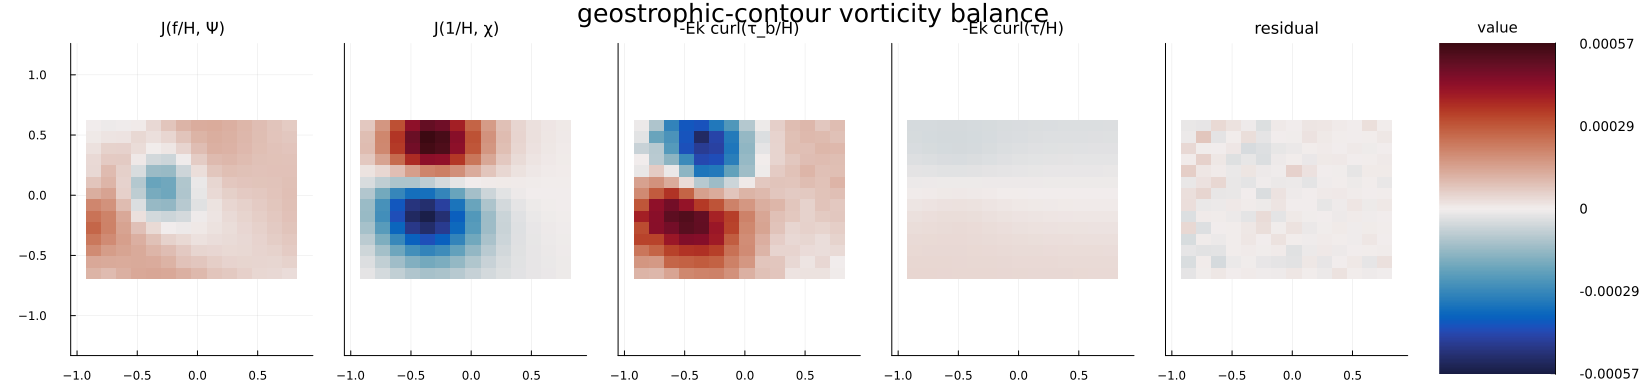

In [12]:
gcvb = compute_geostrophic_contour_vorticity_diagnostics(
    solution, diagnostics,
)
display(performance_summary(gcvb))

gcvb_figure = plot_geostrophic_contour_vorticity_balance(
    gcvb;
    output=joinpath(@__DIR__, "sample_pg_geostrophic_contour_vorticity_balance.png"),
)
display(gcvb_figure)

## Transport-divergence vorticity balance

Compute and plot the bottom-pressure torque, baroclinic torque, Coriolis-weighted bottom- and surface-stress curls, and closure residual in equation (46).

┌ Info: TDVB diagnostic calculation started
│   Nx = 16
│   Ny = 16
│   wet_points = 256
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1676
┌ Info: Starting sampling transport-divergence vorticity terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: TDVB diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 16
│   percent = 6.2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1694
┌ Info: TDVB diagnostic sampling progress
│   rows_

(sampling = (seconds = 0.027875916, allocated_mib = 46.38316345214844, gc_seconds = 0.0), total_seconds = 0.028184890747070312, relative_l2_residual = 0.05052941325676389)

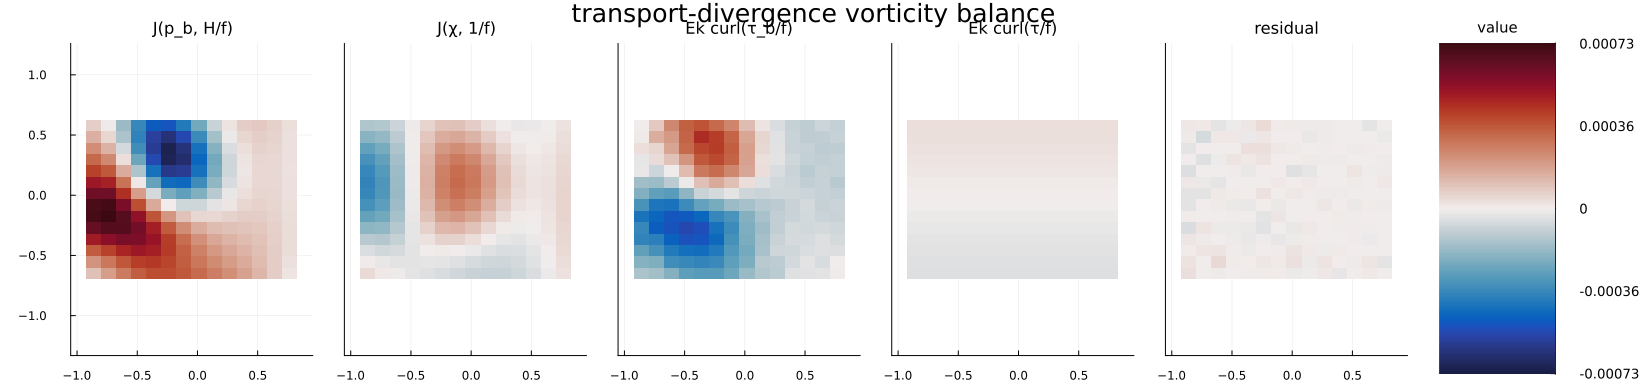

In [13]:
tdvb = compute_transport_divergence_vorticity_diagnostics(
    solution, diagnostics,
)
display(performance_summary(tdvb))

tdvb_figure = plot_transport_divergence_vorticity_balance(
    tdvb;
    output=joinpath(@__DIR__, "sample_pg_transport_divergence_vorticity_balance.png"),
)
display(tdvb_figure)

## Surface-pressure equation coefficients

Compute and plot the advection velocity, diffusivity, and separate baroclinic and surface-stress source fields in the surface-pressure equation (74).

┌ Info: Surface-pressure equation diagnostic calculation started
│   Nx = 16
│   Ny = 16
│   wet_points = 256
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1810
┌ Info: Starting sampling surface-pressure equation coefficients
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Surface-pressure equation diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 16
│   percent = 6.2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1834
┌ Info:

(sampling = (seconds = 0.007968209, allocated_mib = 21.320892333984375, gc_seconds = 0.0), total_seconds = 0.008235931396484375, sampled_wet_points = 256, wet_points = 196, points_per_second = 24597.748377332973, relative_l2_residual = 0.1528084792157114)

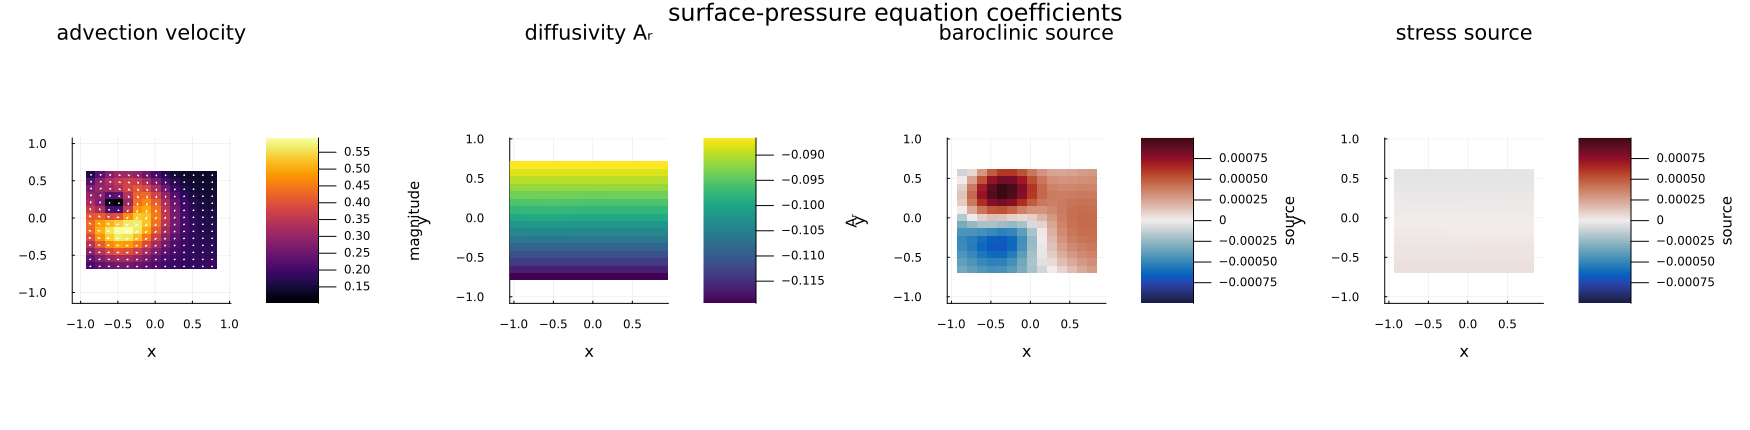

In [14]:
pressure_equation = compute_surface_pressure_equation_diagnostics(
    solution, diagnostics,
)
display(performance_summary(pressure_equation))

pressure_equation_figure = plot_surface_pressure_equation_diagnostics(
    pressure_equation;
    output=joinpath(@__DIR__, "sample_pg_surface_pressure_equation.png"),
)
display(pressure_equation_figure)